Lab 8 - Charlie Caravati

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numpy.linalg import inv 

In [7]:
def driver():
    
    f = lambda x: 1 / (1 + (10*x)**2)
    a = -1
    b = 1
    
    ''' create points you want to evaluate at'''
    Neval = 100
    xeval =  np.linspace(a,b,Neval)
    
    ''' number of intervals'''
    Nint = 10
    
    '''evaluate the linear spline'''
    yeval, norm1, norm2 = eval_lin_spline(xeval,Neval,a,b,f,Nint)
    
    ''' evaluate f at the evaluation points'''
    fex = f(xeval)
      
    plt.plot(xeval,fex,'ro-',label='exact function')
    plt.plot(xeval,yeval,'bs--',label='natural spline') 
    plt.legend
    plt.show()

     
     
    err = abs(yeval-fex)
    plt.figure() 
    plt.semilogy(xeval,err,'ro--',label='absolute error')
    plt.legend()
    plt.show()

    maxnorm = norms(f, xeval, yeval)
    print(maxnorm)

    plt.figure()
    plt.plot(norm1, 'ro-', label='1-norm error')
    plt.plot(norm2, 'bs-', label='2-norm error')
    plt.xlabel('Interval Index')
    plt.ylabel('Error Norm')
    plt.legend()
    plt.show()

In [3]:
def eval_line(alpha, x0, fx0, x1, fx1):
  """Evaluates the line passing through (x0, fx0) and (x1, fx1) at point alpha."""
  new_line = fx0 + (fx1 - fx0) / (x1 - x0) * (alpha - x0)
  return new_line

In [4]:
def norms(f, xeval, yeval):

    fex = f(xeval)
    maxnorm = np.linalg.norm(fex - yeval, ord =np.inf)/np.linalg.norm(fex, ord = np.inf)

    return maxnorm

In [5]:
def  eval_lin_spline(xeval,Neval,a,b,f,Nint):

    '''create the intervals for piecewise approximations'''
    xint = np.linspace(a,b,Nint+1)
   
    '''create vector to store the evaluation of the linear splines'''
    yeval = np.zeros(Neval) 
        
    norm1_list = []
    norm2_list = []
    
    for jint in range(Nint):
        '''find indices of xeval in interval (xint(jint),xint(jint+1))'''
        '''let ind denote the indices in the intervals'''
        '''let n denote the length of ind'''
        
        '''temporarily store your info for creating a line in the interval of 
        interest'''
        a1= xint[jint]
        fa1 = f(a1)
        b1 = xint[jint+1]
        fb1 = f(b1)

        if jint == Nint - 1:
            ind = np.where((xeval >= a1) & (xeval <= b1))[0]
        else:
            ind = np.where((xeval >= a1) & (xeval < b1))[0]

        n = len(ind)

        for kk in range(n):
            # yeval(ind(kk)) = call your line evaluator at xeval(ind(kk)) with the points (a1,fa1) and (b1,fb1)
           
            idx = ind[kk]
            yeval[idx] = eval_line(xeval[idx], a1, fa1, b1, fb1)

        err_sub = f(xeval[ind]) - yeval[ind]
        norm1_list.append(np.linalg.norm(err_sub, ord=1))
        norm2_list.append(np.linalg.norm(err_sub, ord=2))
    
    return yeval, norm1_list, norm2_list

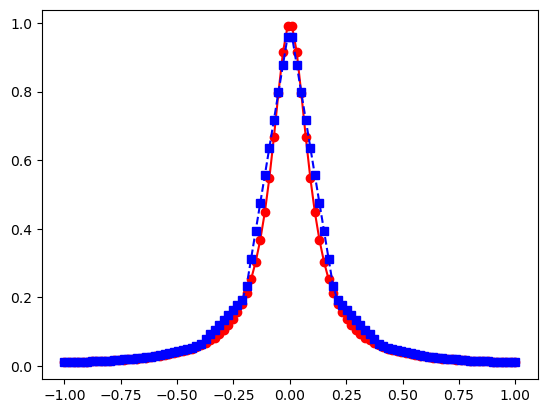

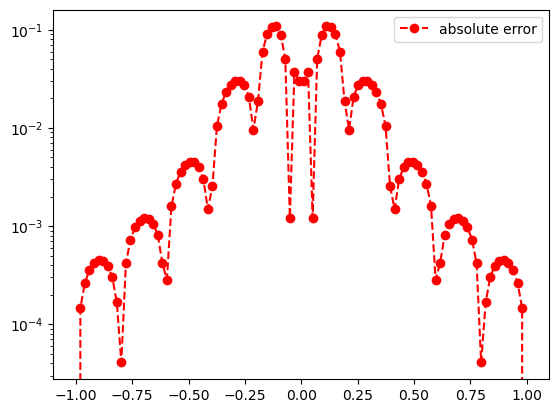

0.1091440976851251


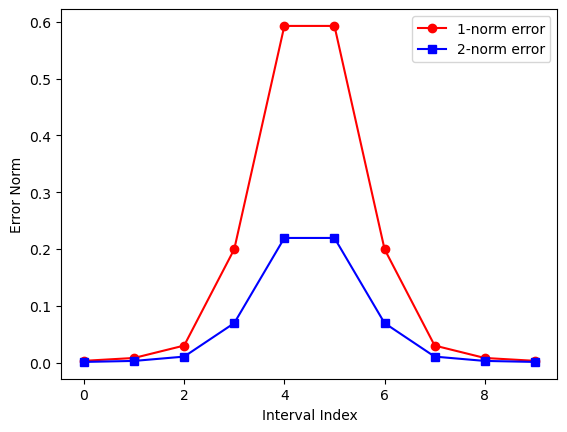

In [8]:
driver()

This performs well and is an improvement over global interpolation with uniform nodes. Linear splines get relatively worse as the close the function is the 0.